# Takei 2025 cerebellum — ChromData walkthrough + paper reproductions

A single notebook that walks through everything stored in the
`takei2025_cerebellum_rep1.h5cd` produced by the U-Chrom loader, then
reproduces five panels from the Takei et al. 2025 *Nature* paper
"Spatial multi-omics reveals cell-type-specific nuclear compartments"
(doi:[10.1038/s41586-025-08838-x](https://www.nature.com/articles/s41586-025-08838-x),
Zenodo record [7693825](https://zenodo.org/records/7693825)).

**Parts**

1. Load data — auto-discover a pre-built `.h5cd`, fall back to the
   in-repo small fixture.
2. ChromData field-by-field inspection — `coords`, `spots`, `tracks`,
   `cells`, `cellm`, `traces`, `uns`.
3. Subsetting & distance API demo.
4. Paper reproductions (5 figures, all inline):
   - UMAP painted by cell type
   - Cell-type × marker median heatmap
   - Fig 5a — per-1Mb-bin spatial distance heatmaps on chr4
   - Fig 5c — inter-chromosomal distance ECDFs by top-5% marker bins
   - Fig 3f — RNAPIISer5-P z-score tracks along long-gene regions
5. Framework gap notes.


## 1. Load the data

Auto-detects a pre-built `.h5cd` (rep1 / rep2 / pos0) generated by `ChromData.from_seqfish_multiomics`; falls back to the small in-repo fixture when nothing local is found.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
from uchrom.core import ChromData

def _repo_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'pyproject.toml').exists() or (p / 'example-data').exists():
            return p
    return Path.cwd()

def find_takei2025_cerebellum_h5cd():
    for p in [
        Path('/Volumes/Extreme SSD/U-Chrom_outputs/takei2025_cerebellum_rep1.h5cd'),
        Path('/Volumes/Extreme SSD/U-Chrom_outputs/takei2025_cerebellum_rep2.h5cd'),
        Path.home() / 'Downloads' / 'U-Chrom_data' / 'takei2025_cerebellum_rep1.h5cd',
        Path.home() / 'Downloads' / 'U-Chrom_data' / 'takei2025_cerebellum_rep1_pos0.h5cd',
    ]:
        if p.exists():
            return p
    return None

h5cd = find_takei2025_cerebellum_h5cd()
if h5cd is not None:
    print(f'[data] using pre-built {h5cd}')
    cd = ChromData.read(h5cd)
    DATA_MODE = 'real'
else:
    fix = _repo_root() / 'example-data' / 'takei2025_cerebellum_fixture'
    print(f'[data] no pre-built .h5cd; falling back to fixture at {fix}')
    cd = ChromData.from_seqfish_multiomics(
        spot_glob=str(fix / 'dna_spots.csv'),
        locus_annotation=str(fix / 'locus_annotation.csv'),
        cell_clustering=str(fix / 'clustering.csv'),
    )
    DATA_MODE = 'fixture'
print(cd)


[data] using pre-built /Volumes/Extreme SSD/U-Chrom_outputs/takei2025_cerebellum_rep1.h5cd


ChromData: n_spots=10912638, n_traces=59112, n_cells=1799
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'name']
  cells:   ['leiden', 'cell_type', 'x_centroid', 'y_centroid', 'z_centroid', 'nuc_volume_um3', 'doublet', 'batch'] (1799 cells)
  cellm:   {'umap': (1799, 2)}
  tracks:  ['CPSF6', 'ATRX', 'H4K8ac', 'HDAC2', 'H3K9ac', 'H3K9me3', 'H3K9me2', 'RNAPIISer2-P', 'H3', 'H3K36me2', 'UBTF', 'LaminB1', 'RNAPIISer5-P', 'RYBP', 'HP1beta', 'RING1B', 'H2A.X', 'H3K4me1', 'H4K20me2', 'H3K27me2', 'JARID2', 'SF3A66', 'CBP', 'H2AK119u1', 'EZH2', 'H3K4me2', 'BRG1', 'HP1alpha', 'Fibrillarin', 'KAP1', 'H3K27ac', 'H3K4me3', 'H3K36ac', 'H3K14ac', 'H4K20me1', 'HP1gamma', 'H4K20me3', 'H3K27me3', 'mH2A1', 'CHD4', 'KAT3B_p300', 'H3K56ac', 'H3K36me3', 'HDAC1', 'SUZ12', 'H4K16ac', 'BRD4', 'SOX2', 'rDNA', 'MajSat', 'LINE1', 'SINEB1', 'Telomere', 'MinSat', 'Xist_RNA', 'ITS1_RNA', 'Rnu2_RNA', 'polyA_RNA', 'Malat1_RNA', 'dot_int', 'n_rad_score', 'n_per_dist(um)']
  traces:  ['dbscan_allele', 'dbsc

## 2. ChromData inspection

A `ChromData` aggregates one experiment's structure data into named components.  Each cell below shows one component and how to access it.  Schema summary:

| field | type | role |
|---|---|---|
| `coords` | `(n_spots, 3) float64` | μm coordinate per spot |
| `spots` | DataFrame | chrom / start / end / trace_id / cell_id |
| `tracks` | DataFrame | per-spot signal (62 z-score / derived columns) |
| `cells` | DataFrame | per-cell metadata, **indexed by cell_id** |
| `cellm` | dict of ndarrays | per-cell multi-dim arrays (e.g. UMAP) |
| `traces` | DataFrame | per-trace metadata, **indexed by trace_id** |
| `uns` | dict | global metadata |


### 2.1 `coords` — per-spot 3D positions


In [2]:
print(f'shape : {cd.coords.shape}')
print(f'dtype : {cd.coords.dtype}')
print(f'first 5 rows (μm):')
print(cd.coords[:5])


shape : (10912638, 3)
dtype : float64
first 5 rows (μm):
[[131.758424 107.129991   1.606   ]
 [132.623212 109.05331    1.62025 ]
 [132.47963  107.992513   1.59625 ]
 [135.733297 108.514723   1.584   ]
 [133.746015 107.105786   1.6115  ]]


### 2.2 `spots` — per-spot identifiers


In [3]:
print(f'shape   : {cd.spots.shape}')
print('dtypes  :')
print(cd.spots.dtypes)
print('\nhead:')
print(cd.spots.head())
print('\nchrom value counts (first 10):')
print(cd.spots['chrom'].value_counts().head(10))


shape   : (10912638, 6)
dtypes  :
chrom       category
start          int64
end            int64
trace_id    category
cell_id     category
name          object
dtype: object

head:
   chrom     start       end          trace_id  cell_id        name
0  chr10  37950000  37975000  1_0_270_chr10_a1  1_0_270  chr10-1393
1   chr5  68900000  68925000   1_0_270_chr5_a1  1_0_270   chr5-2621
2   chr5  82425000  82450000   1_0_270_chr5_a1  1_0_270   chr5-3162
3   chrX  81925000  81950000   1_0_270_chrX_a1  1_0_270   chrX-3076
4  chr14  94925000  94950000  1_0_270_chr14_a1  1_0_270  chr14-3669

chrom value counts (first 10):
chrom
chr1     894280
chr2     838820
chr3     753858
chr4     698048
chr6     679287
chr10    633692
chr8     575384
chr7     552546
chr9     550073
chr5     544520
Name: count, dtype: int64


### 2.3 `tracks` — 62 per-spot epigenomic signals

59 z-score columns (IF + DNA-FISH repeats + RNA-FISH probes) plus `dot_int / n_rad_score / n_per_dist(um)`.  In rep2 the columns `LINE1` and `SINEB1` are NaN (those probes were not in rep2).


In [4]:
print(f'shape : {cd.tracks.shape}')
print(f'\n62 columns:')
for i in range(0, len(cd.tracks.columns), 8):
    print('  ' + ', '.join(cd.tracks.columns[i:i+8]))
print('\nhead (first 5 columns × 5 rows):')
print(cd.tracks.iloc[:5, :5])
print('\nbasic stats on a few markers:')
print(cd.tracks[['H3K27me3', 'LaminB1', 'RNAPIISer5-P', 'SF3A66']].describe().round(2))


shape : (10912638, 62)

62 columns:
  CPSF6, ATRX, H4K8ac, HDAC2, H3K9ac, H3K9me3, H3K9me2, RNAPIISer2-P
  H3, H3K36me2, UBTF, LaminB1, RNAPIISer5-P, RYBP, HP1beta, RING1B
  H2A.X, H3K4me1, H4K20me2, H3K27me2, JARID2, SF3A66, CBP, H2AK119u1
  EZH2, H3K4me2, BRG1, HP1alpha, Fibrillarin, KAP1, H3K27ac, H3K4me3
  H3K36ac, H3K14ac, H4K20me1, HP1gamma, H4K20me3, H3K27me3, mH2A1, CHD4
  KAT3B_p300, H3K56ac, H3K36me3, HDAC1, SUZ12, H4K16ac, BRD4, SOX2
  rDNA, MajSat, LINE1, SINEB1, Telomere, MinSat, Xist_RNA, ITS1_RNA
  Rnu2_RNA, polyA_RNA, Malat1_RNA, dot_int, n_rad_score, n_per_dist(um)

head (first 5 columns × 5 rows):
     CPSF6     ATRX   H4K8ac   HDAC2  H3K9ac
0 -1.08130 -1.10790 -1.07040 -1.2173 -1.3996
1 -0.78539 -0.91556 -1.06820 -1.0802 -1.2301
2 -0.87785 -0.99531 -0.75016 -1.1195 -1.0257
3 -0.82664 -0.93198 -0.97345 -1.0111 -1.3189
4 -0.78823 -0.96247 -0.75354 -1.0791 -1.4937

basic stats on a few markers:


          H3K27me3      LaminB1  RNAPIISer5-P       SF3A66
count  10912638.00  10912638.00   10912638.00  10912638.00
mean          0.31         0.31          0.28         0.16
std           0.99         1.09          0.96         0.99
min          -2.53        -2.47         -2.30        -3.64
25%          -0.33        -0.48         -0.50        -0.38
50%           0.15         0.08          0.18        -0.12
75%           0.76         0.85          0.97         0.33
max          23.54        31.91         15.08        28.28


### 2.4 `cells` — per-cell metadata

`cells.index` is the composite cell_id (`{rep}_{fov}_{cellID}`).  Each row carries leiden cluster, cell_type label (after applying `uns['leiden_to_cell_type']`), 3D centroid, nuclear volume, doublet flag, batch.


In [5]:
print(f'shape  : {cd.cells.shape}')
print(f'index  : {cd.cells.index.name!r}, first 5 ids = {cd.cells.index[:5].tolist()}')
print('\nhead:')
print(cd.cells.head())
print('\ncell_type counts:')
print(cd.cells['cell_type'].value_counts())


shape  : (1799, 8)
index  : 'cell_id', first 5 ids = ['1_0_42', '1_0_47', '1_0_69', '1_0_72', '1_0_73']

head:
         leiden cell_type  x_centroid  y_centroid  z_centroid  nuc_volume_um3  \
cell_id                                                                         
1_0_42        0   Granule    1882.598    1580.253      12.786         131.695   
1_0_47        0   Granule     624.847    1731.403      13.590         163.495   
1_0_69        0   Granule    1983.711    1591.343      14.482         109.238   
1_0_72        0   Granule    1255.603    1677.512      13.784         117.001   
1_0_73        0   Granule    1886.033    1829.907      13.430         137.986   

         doublet  batch  
cell_id                  
1_0_42         0      1  
1_0_47         0      1  
1_0_69         0      1  
1_0_72         0      1  
1_0_73         0      1  

cell_type counts:
cell_type
Granule     1109
Other        323
Bergmann     192
MLI1          90
Purkinje      58
MLI2+PLI      27
Name: co

### 2.5 `cellm` — per-cell multi-dim arrays

Right now only contains `umap` (2-D).  Per loader roadmap, `cellm['if_mean']` (27-marker per-cell mean IF, P2) is the next key to land here.


In [6]:
print(f'cellm keys: {list(cd.cellm)}')
for k, v in cd.cellm.items():
    print(f'  {k}: shape={v.shape}, dtype={v.dtype}')
print('\numap first 5 rows:')
print(cd.cellm['umap'][:5])


cellm keys: ['umap']
  umap: shape=(1799, 2), dtype=float64

umap first 5 rows:
[[ 6.8091545 10.963283 ]
 [ 6.307696  10.393372 ]
 [ 6.173099  11.890781 ]
 [ 9.671131  13.740751 ]
 [10.064677  10.373851 ]]


### 2.6 `traces` — per-trace diagnostics

Index is `trace_id` (`{rep}_{fov}_{cellID}_{chrom}_a{allele}`).  Carries the non-canonical DBSCAN allele numbers as diagnostics (the canonical one is already encoded in `trace_id`).


In [7]:
print(f'shape : {cd.traces.shape}')
print(f'index : {cd.traces.index.name!r}, first 5 trace_ids:')
print(cd.traces.index[:5].tolist())
print('\nhead:')
print(cd.traces.head())


shape : (59112, 2)
index : 'trace_id', first 5 trace_ids:
['1_0_270_chr10_a1', '1_0_270_chr5_a1', '1_0_270_chrX_a1', '1_0_270_chr14_a1', '1_0_270_chr17_a1']

head:
                  dbscan_allele  dbscan_ldp_allele
trace_id                                          
1_0_270_chr10_a1              1                  1
1_0_270_chr5_a1               1                 -1
1_0_270_chrX_a1               1                  1
1_0_270_chr14_a1              1                  1
1_0_270_chr17_a1              1                  1


### 2.7 `uns` — global metadata


In [8]:
for k, v in cd.uns.items():
    if isinstance(v, dict):
        print(f'  {k}: dict({len(v)} keys)')
        for sk, sv in list(v.items())[:5]:
            print(f'      {sk}: {sv}')
        if len(v) > 5:
            print(f'      … ({len(v)-5} more)')
    else:
        print(f'  {k}: {v}')


  allele_col: dbscan_ldp_nbr_allele
  genome_assembly: mm10
  keep_unclustered: False
  source: Takei2025_cerebellum
  voxel_xy_nm: 103
  voxel_z_nm: 250
  xyz_unit: um
  zenodo_record: 7693825
  leiden_to_cell_type: dict(7 keys)
      0: Granule
      1: Granule
      11: Purkinje
      2: Bergmann
      4: MLI1
      … (2 more)


### 2.8 Convenience properties


In [9]:
print(f'n_spots  : {cd.n_spots:,}')
print(f'n_traces : {cd.n_traces:,}')
print(f'n_cells  : {cd.n_cells:,}')
print(f'chroms   : {cd.chroms}')


n_spots  : 10,912,638
n_traces : 59,112
n_cells  : 1,799
chroms   : ['chr1', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chrX']


## 3. Subsetting and distance API

All three accessors return a **new** `ChromData` that keeps `coords / spots / tracks / cells / cellm / traces` consistent with one another.  Nothing is mutated in place.


In [10]:
# Per-chrom subset.
sub_chrom = cd.get_chrom('chr4') if 'chr4' in cd.chroms else cd.get_chrom(cd.chroms[0])
print(f'after get_chrom({sub_chrom.spots["chrom"].iloc[0]!r}):')
print(sub_chrom)


after get_chrom('chr4'):
ChromData: n_spots=698048, n_traces=2955, n_cells=1762
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'name']
  cells:   ['leiden', 'cell_type', 'x_centroid', 'y_centroid', 'z_centroid', 'nuc_volume_um3', 'doublet', 'batch'] (1762 cells)
  cellm:   {'umap': (1762, 2)}
  tracks:  ['CPSF6', 'ATRX', 'H4K8ac', 'HDAC2', 'H3K9ac', 'H3K9me3', 'H3K9me2', 'RNAPIISer2-P', 'H3', 'H3K36me2', 'UBTF', 'LaminB1', 'RNAPIISer5-P', 'RYBP', 'HP1beta', 'RING1B', 'H2A.X', 'H3K4me1', 'H4K20me2', 'H3K27me2', 'JARID2', 'SF3A66', 'CBP', 'H2AK119u1', 'EZH2', 'H3K4me2', 'BRG1', 'HP1alpha', 'Fibrillarin', 'KAP1', 'H3K27ac', 'H3K4me3', 'H3K36ac', 'H3K14ac', 'H4K20me1', 'HP1gamma', 'H4K20me3', 'H3K27me3', 'mH2A1', 'CHD4', 'KAT3B_p300', 'H3K56ac', 'H3K36me3', 'HDAC1', 'SUZ12', 'H4K16ac', 'BRD4', 'SOX2', 'rDNA', 'MajSat', 'LINE1', 'SINEB1', 'Telomere', 'MinSat', 'Xist_RNA', 'ITS1_RNA', 'Rnu2_RNA', 'polyA_RNA', 'Malat1_RNA', 'dot_int', 'n_rad_score', 'n_per_dist(um)']
  traces:  [

In [11]:
# Per-cell subset.
some_cell = cd.cells.index[0]
sub_cell = cd.get_cell(some_cell)
print(f'after get_cell({some_cell!r}):')
print(sub_cell)


after get_cell('1_0_42'):
ChromData: n_spots=4183, n_traces=24, n_cells=1
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'name']
  cells:   ['leiden', 'cell_type', 'x_centroid', 'y_centroid', 'z_centroid', 'nuc_volume_um3', 'doublet', 'batch'] (1 cells)
  cellm:   {'umap': (1, 2)}
  tracks:  ['CPSF6', 'ATRX', 'H4K8ac', 'HDAC2', 'H3K9ac', 'H3K9me3', 'H3K9me2', 'RNAPIISer2-P', 'H3', 'H3K36me2', 'UBTF', 'LaminB1', 'RNAPIISer5-P', 'RYBP', 'HP1beta', 'RING1B', 'H2A.X', 'H3K4me1', 'H4K20me2', 'H3K27me2', 'JARID2', 'SF3A66', 'CBP', 'H2AK119u1', 'EZH2', 'H3K4me2', 'BRG1', 'HP1alpha', 'Fibrillarin', 'KAP1', 'H3K27ac', 'H3K4me3', 'H3K36ac', 'H3K14ac', 'H4K20me1', 'HP1gamma', 'H4K20me3', 'H3K27me3', 'mH2A1', 'CHD4', 'KAT3B_p300', 'H3K56ac', 'H3K36me3', 'HDAC1', 'SUZ12', 'H4K16ac', 'BRD4', 'SOX2', 'rDNA', 'MajSat', 'LINE1', 'SINEB1', 'Telomere', 'MinSat', 'Xist_RNA', 'ITS1_RNA', 'Rnu2_RNA', 'polyA_RNA', 'Malat1_RNA', 'dot_int', 'n_rad_score', 'n_per_dist(um)']
  traces:  ['dbscan_alle

after get_trace('1_0_270_chr10_a1'): n_spots = 818

distance matrix shape = (818, 818), median(off-diag) = 4.82 μm


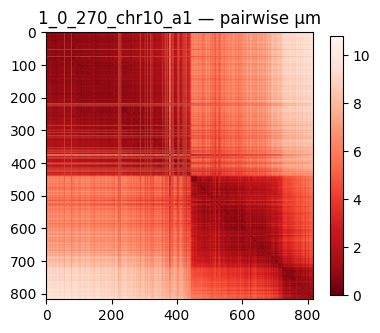

In [12]:
# Per-trace subset + pairwise distance matrix.
some_trace = cd.spots['trace_id'].iloc[0]
sub_trace = cd.get_trace(some_trace)
print(f'after get_trace({some_trace!r}): n_spots = {sub_trace.n_spots}')

D = cd.compute_distances(trace_id=some_trace)
print(f'\ndistance matrix shape = {D.shape}, median(off-diag) = {np.nanmedian(D[D > 0]):.2f} μm')
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(D, cmap='Reds_r')
ax.set_title(f'{some_trace} — pairwise μm')
plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout(); plt.show()


## 4. Paper reproductions

Five panels.  All inputs come from existing ChromData fields; figures are rendered inline (no `plt.savefig`).


### 4.1 UMAP painted by cell_type

**Fields used**: `cellm['umap']`, `cells['cell_type']`.


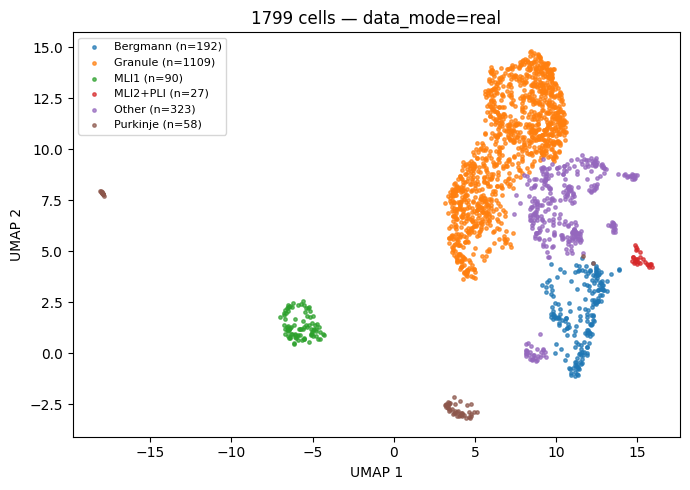

In [13]:
umap = cd.cellm['umap']
ctype = cd.cells['cell_type'].astype(str).values
fig, ax = plt.subplots(figsize=(7, 5))
for t in sorted(set(ctype)):
    m = (ctype == t)
    ax.scatter(umap[m, 0], umap[m, 1], s=6, alpha=0.7,
               label=f'{t} (n={int(m.sum())})')
ax.legend(loc='best', fontsize=8)
ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2')
ax.set_title(f'{cd.n_cells} cells — data_mode={DATA_MODE}')
plt.tight_layout(); plt.show()


### 4.2 Cell-type × marker median heatmap

Median z-score per (cell_type, marker) over all spots of that cell type.  Uses `groupby` on an external Series — *never* copies the full `tracks` frame (matters on rep2 where that would be ~10 GB).


aggregated 6 cell types × 59 markers


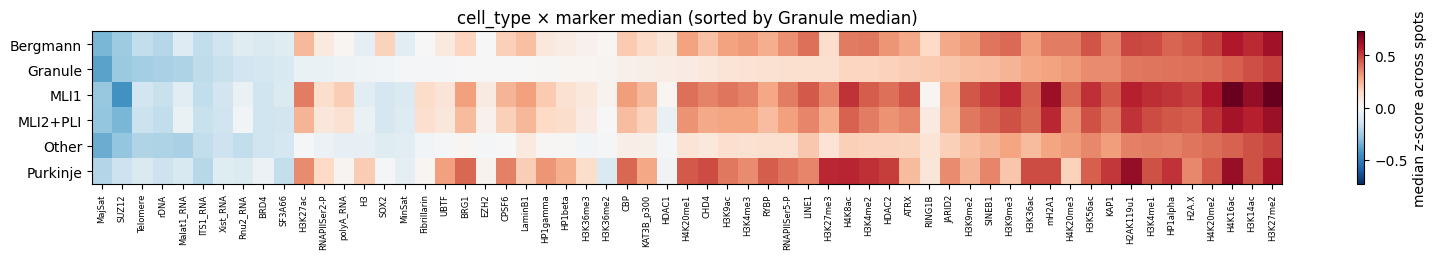

In [14]:
ct_map = cd.cells['cell_type'].to_dict()
spot_ct = cd.spots['cell_id'].astype(str).map(ct_map).fillna('Unknown')

zcols = [c for c in cd.tracks.columns
         if c not in ('dot_int', 'n_rad_score', 'n_per_dist(um)')]
H = (cd.tracks[zcols]
       .groupby(spot_ct.values, observed=True)
       .median(numeric_only=True))
print(f'aggregated {len(H)} cell types × {H.shape[1]} markers')

ref_row = 'Granule' if 'Granule' in H.index else H.index[0]
order = H.columns[np.argsort(H.loc[ref_row].values)]
H_ord = H[order]

fig, ax = plt.subplots(figsize=(16, max(2, 0.45 * len(H_ord))))
v = float(np.nanmax(np.abs(H_ord.values)))
im = ax.imshow(H_ord.values, aspect='auto', cmap='RdBu_r', vmin=-v, vmax=v)
ax.set_yticks(range(len(H_ord.index))); ax.set_yticklabels(H_ord.index)
ax.set_xticks(range(len(H_ord.columns)))
ax.set_xticklabels(H_ord.columns, rotation=90, fontsize=6)
plt.colorbar(im, ax=ax, label='median z-score across spots')
ax.set_title(f'cell_type × marker median (sorted by {ref_row} median)')
plt.tight_layout(); plt.show()


### 4.3 Fig 5a — chr4 per-1Mb-bin spatial distance heatmaps

Three cell types (Purkinje / MLI1 / Bergmann) × one chromosome (chr4).
**Paper-style** pipeline: for each trace, take the per-bin median 3-D
coord, then build that trace's own (n_bins × n_bins) pairwise-distance
matrix; average those matrices across all traces of the cell type —
i.e. the mean **of distances**, NOT the distance of the mean structure
(the two are not equivalent on single-cell FISH data).  Side / top
tracks: per-bin median of four chromatin markers.

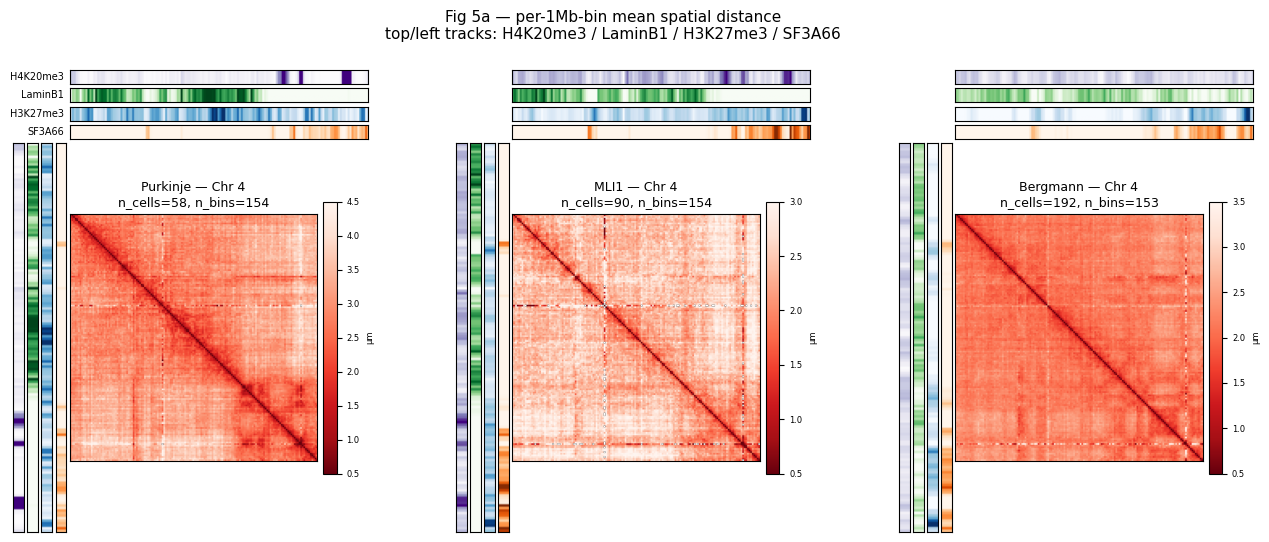

In [15]:
CELL_TYPES_5A = ['Purkinje', 'MLI1', 'Bergmann']
TARGET_CHROM = 'chr4' if 'chr4' in cd.chroms else cd.chroms[0]
MARKERS_5A = ['H4K20me3', 'LaminB1', 'H3K27me3', 'SF3A66']
BIN_SIZE_5A = 1_000_000
MARKER_CMAP = {'H4K20me3': 'Purples', 'LaminB1': 'Greens',
               'H3K27me3': 'Blues',   'SF3A66':  'Oranges'}
MARKER_VMAX = {'H4K20me3': 1.5, 'LaminB1': 0.8,
               'H3K27me3': 1.5, 'SF3A66':  1.5}
PANEL_VMAX_5A = {'Purkinje': 4.5, 'MLI1': 3.0, 'Bergmann': 3.5}

def per_ct_chrom_mean_distance(cd, cell_type, chrom):
    """Paper-style: per-trace pairwise distance matrix, averaged across
    traces (mean of distances, NOT distance of the mean structure)."""
    cells_ct = cd.cells.index[cd.cells['cell_type'] == cell_type]
    if len(cells_ct) == 0:
        return None
    sub = cd.get_chrom(chrom)
    if sub.n_spots == 0:
        return None
    keep = sub.spots['cell_id'].astype(str).isin(cells_ct).values
    if keep.sum() == 0:
        return None
    coords_s = sub.coords[keep]
    sp = sub.spots.iloc[keep].copy()
    sp['_bin'] = (sp['start'].astype(np.int64) // BIN_SIZE_5A).astype(np.int64)
    sp['_x']=coords_s[:,0]; sp['_y']=coords_s[:,1]; sp['_z']=coords_s[:,2]
    # Per-trace, per-bin median 3-D coord.
    pertrace = (sp.groupby(['trace_id', '_bin'], observed=True)
                  [['_x','_y','_z']].median())
    all_bins = np.sort(pertrace.index.get_level_values('_bin').unique().to_numpy())
    n_bins = len(all_bins)
    if n_bins < 2:
        return None
    bin_idx = {int(b): i for i, b in enumerate(all_bins)}
    # Accumulate each trace's pairwise distance matrix into a global
    # (bin x bin) sum + count, then divide -> mean of per-trace distances.
    D_sum   = np.zeros((n_bins, n_bins), dtype=np.float64)
    D_count = np.zeros((n_bins, n_bins), dtype=np.int32)
    for _, grp in pertrace.groupby(level='trace_id', observed=True):
        coords = grp[['_x','_y','_z']].to_numpy()
        obs_bins = grp.index.get_level_values('_bin').to_numpy()
        obs_idx = np.fromiter((bin_idx[int(b)] for b in obs_bins),
                              dtype=np.int32, count=len(obs_bins))
        if obs_idx.size < 2:
            continue
        d = np.sqrt(((coords[:, None] - coords[None, :]) ** 2).sum(-1))
        np.add.at(D_sum,   (obs_idx[:, None], obs_idx[None, :]), d)
        np.add.at(D_count, (obs_idx[:, None], obs_idx[None, :]), 1)
    D_mean = np.where(D_count > 0, D_sum / np.maximum(D_count, 1), np.nan)
    bin_marker = {}
    for m in MARKERS_5A:
        tk = sub.tracks[m].iloc[keep]
        bin_marker[m] = tk.groupby(sp['_bin'].values).median().reindex(all_bins).values
    return {'bins': all_bins, 'D': D_mean,
            'bin_marker': pd.DataFrame(bin_marker, index=all_bins)}

results_5a = {ct: per_ct_chrom_mean_distance(cd, ct, TARGET_CHROM) for ct in CELL_TYPES_5A}

def _panel_5a(fig, outer_spec, ct, info, chrom):
    if info is None:
        ax = fig.add_subplot(outer_spec)
        ax.text(0.5, 0.5, f'no data\n{ct} {chrom}',
                ha='center', va='center', fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
        return
    inner = gridspec.GridSpecFromSubplotSpec(
        5, 5, subplot_spec=outer_spec,
        width_ratios=[1,1,1,1,28], height_ratios=[1,1,1,1,28],
        wspace=0.05, hspace=0.05,
    )
    bm = info['bin_marker']
    for i, m in enumerate(MARKERS_5A):
        ax_h = fig.add_subplot(inner[i, -1])
        ax_h.imshow(bm[m].values.reshape(1, -1), aspect='auto',
                    cmap=MARKER_CMAP[m], vmin=0, vmax=MARKER_VMAX[m])
        ax_h.set_xticks([]); ax_h.set_yticks([])
        if ct == CELL_TYPES_5A[0]:
            ax_h.set_ylabel(m, rotation=0, ha='right', va='center', fontsize=7)
    for j, m in enumerate(MARKERS_5A):
        ax_v = fig.add_subplot(inner[-1, j])
        ax_v.imshow(bm[m].values.reshape(-1, 1), aspect='auto',
                    cmap=MARKER_CMAP[m], vmin=0, vmax=MARKER_VMAX[m])
        ax_v.set_xticks([]); ax_v.set_yticks([])
    ax_m = fig.add_subplot(inner[-1, -1])
    im = ax_m.imshow(info['D'], aspect='equal', cmap='Reds_r',
                     vmin=0.5, vmax=PANEL_VMAX_5A.get(ct, 4.5))
    ax_m.set_xticks([]); ax_m.set_yticks([])
    n_cells = int((cd.cells['cell_type'] == ct).sum())
    ax_m.set_title(f'{ct} — Chr {chrom[3:]}\nn_cells={n_cells}, '
                   f'n_bins={info["D"].shape[0]}', fontsize=9)
    cb = fig.colorbar(im, ax=ax_m, shrink=0.7, pad=0.02)
    cb.ax.tick_params(labelsize=6); cb.set_label('μm', fontsize=6)

fig = plt.figure(figsize=(16, 6))
outer = gridspec.GridSpec(1, 3, figure=fig, wspace=0.25)
for col, ct in enumerate(CELL_TYPES_5A):
    _panel_5a(fig, outer[col], ct, results_5a[ct], TARGET_CHROM)
fig.suptitle('Fig 5a — per-1Mb-bin mean spatial distance\n'
             'top/left tracks: H4K20me3 / LaminB1 / H3K27me3 / SF3A66',
             fontsize=11)
plt.show()


### 4.4 Fig 5c — inter-chrom ECDF stratified by top-5% marker bins

For each cell type and marker: take the top-5% (chrom, 1-Mb-bin) ensemble median z-score, compute all **inter-chromosomal** pairwise bin-centroid distances within each cell where both endpoints fall in the top-5% set.  Random null = bootstrap (200 iterations) of random bin sets of matched size.  Uses integer-coded keys + numpy boolean masks (~30 s on full rep1).


Purkinje: 94,018,361 inter-chrom 1Mb-bin pairs
MLI1: 141,150,833 inter-chrom 1Mb-bin pairs
Bergmann: 324,960,204 inter-chrom 1Mb-bin pairs


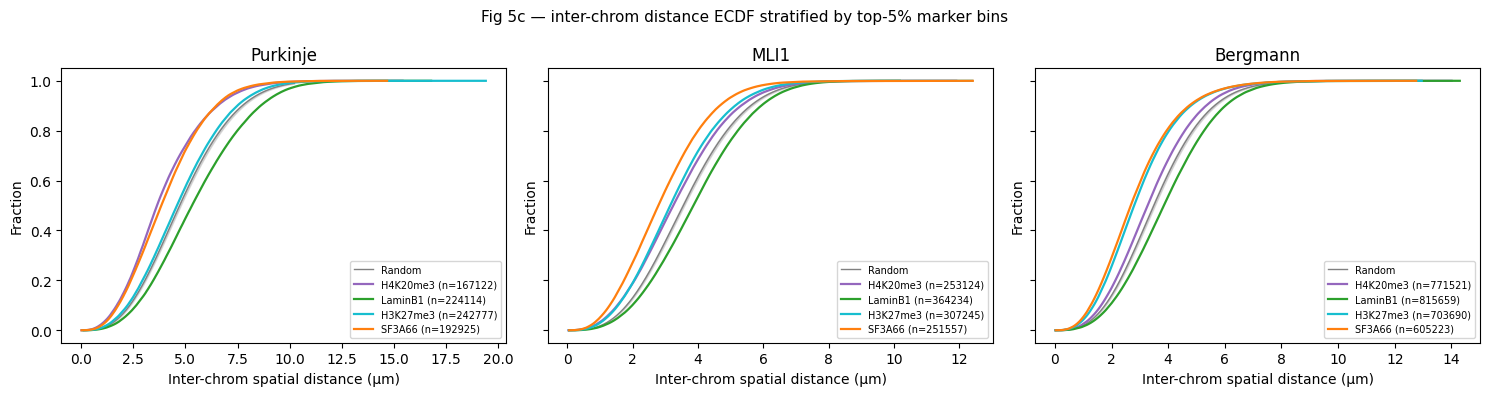

In [16]:
CELL_TYPES_5C = ['Purkinje', 'MLI1', 'Bergmann']
MARKERS_5C = ['H4K20me3', 'LaminB1', 'H3K27me3', 'SF3A66']
MARKER_COLOR = {'H4K20me3': 'tab:purple', 'LaminB1': 'tab:green',
                'H3K27me3': 'tab:cyan',   'SF3A66':  'tab:orange'}
BIN_SIZE_5C = 1_000_000

# Build a global (chrom, bin) → int key.
chrom_arr = cd.spots['chrom'].astype(str).to_numpy()
bin_arr   = (cd.spots['start'].astype(np.int64).to_numpy() // BIN_SIZE_5C)
key_str   = pd.Series(chrom_arr).str.cat(pd.Series(bin_arr).astype(str), sep='|').values
key_cat   = pd.Categorical(key_str)
key_codes = key_cat.codes.astype(np.int32)
chrom_of_key = np.array([s.split('|')[0] for s in key_cat.categories])

def compute_inter_chrom_pairs(cd, cell_type):
    cells_ct = cd.cells.index[cd.cells['cell_type'] == cell_type]
    cell_str = cd.spots['cell_id'].astype(str)
    mask = cell_str.isin(cells_ct).to_numpy()
    if mask.sum() == 0:
        return np.zeros((0, 3), dtype=np.float64)
    df = pd.DataFrame({
        'cell_id': cell_str[mask].values,
        '_key':    key_codes[mask],
        'x':       cd.coords[mask, 0],
        'y':       cd.coords[mask, 1],
        'z':       cd.coords[mask, 2],
    })
    bin_pos = (df.groupby(['cell_id', '_key'], observed=True)
                 [['x', 'y', 'z']].mean().reset_index())
    bin_pos['_chrom_id'] = chrom_of_key[bin_pos['_key'].values]
    out_rows = []
    for cid, grp in bin_pos.groupby('cell_id', observed=True):
        n = len(grp)
        if n < 2: continue
        coords = grp[['x', 'y', 'z']].to_numpy()
        keys = grp['_key'].to_numpy()
        chrs = grp['_chrom_id'].to_numpy()
        i, j = np.triu_indices(n, k=1)
        inter = chrs[i] != chrs[j]
        if not inter.any(): continue
        d = np.sqrt(((coords[i] - coords[j]) ** 2).sum(-1))
        ii, jj = i[inter], j[inter]
        out_rows.append(np.column_stack([keys[ii], keys[jj], d[inter]]))
    if not out_rows:
        return np.zeros((0, 3), dtype=np.float64)
    return np.vstack(out_rows)

def top5_keys(cd, cell_type, markers):
    cells_ct = cd.cells.index[cd.cells['cell_type'] == cell_type]
    cell_str = cd.spots['cell_id'].astype(str)
    mask = cell_str.isin(cells_ct).to_numpy()
    if mask.sum() == 0:
        return {m: np.array([], dtype=np.int32) for m in markers}, np.array([], dtype=np.int32)
    key_sub = key_codes[mask]
    out = {}
    for m in markers:
        vals = cd.tracks[m].iloc[mask].to_numpy()
        bin_med = pd.Series(vals).groupby(key_sub).median()
        thr = bin_med.quantile(0.95)
        out[m] = bin_med.index[bin_med >= thr].to_numpy().astype(np.int32)
    return out, np.unique(key_sub)

def ecdf_y(values, xs):
    if len(values) == 0:
        return np.full_like(xs, np.nan, dtype=float)
    s = np.sort(values)
    return np.searchsorted(s, xs, side='right') / len(s)

ecdf_pairs = {ct: compute_inter_chrom_pairs(cd, ct) for ct in CELL_TYPES_5C}
for ct, arr in ecdf_pairs.items():
    print(f'{ct}: {len(arr):,} inter-chrom 1Mb-bin pairs')

rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, ct in zip(axes, CELL_TYPES_5C):
    pairs = ecdf_pairs[ct]
    if len(pairs) == 0:
        ax.set_title(f'{ct} (no data)'); continue
    key_a = pairs[:, 0].astype(np.int32)
    key_b = pairs[:, 1].astype(np.int32)
    dist = pairs[:, 2]
    top5, obs_keys = top5_keys(cd, ct, MARKERS_5C)
    xs = np.linspace(np.nanpercentile(dist, 1), np.nanpercentile(dist, 99), 200)
    sizes = [len(s) for s in top5.values() if len(s) > 0]
    target = int(np.median(sizes)) if sizes else 50
    # Random null
    boot_y = []
    n_boot = 200
    if obs_keys.size > 0:
        max_key = int(obs_keys.max()) + 2
        for _ in range(n_boot):
            rs = rng.choice(obs_keys, size=min(target, len(obs_keys)), replace=False)
            mark = np.zeros(max_key, dtype=bool); mark[rs] = True
            m1 = mark[key_a] & mark[key_b]
            if m1.sum() == 0:
                boot_y.append(np.full_like(xs, np.nan, dtype=float)); continue
            boot_y.append(ecdf_y(dist[m1], xs))
    boot_y = np.array(boot_y)
    mean = np.nanmean(boot_y, 0); std = np.nanstd(boot_y, 0)
    ax.plot(xs, mean, color='gray', lw=1, label='Random')
    ax.fill_between(xs, mean - std, mean + std, color='gray', alpha=0.25)
    for m, keys in top5.items():
        if len(keys) == 0: continue
        max_k = int(max(obs_keys.max() if obs_keys.size else 0, keys.max())) + 2
        mark = np.zeros(max_k, dtype=bool); mark[keys] = True
        mm = mark[key_a] & mark[key_b]
        if mm.sum() == 0: continue
        d = dist[mm]
        s = np.sort(d)
        y = np.arange(1, len(s) + 1) / len(s)
        ax.plot(s, y, color=MARKER_COLOR[m], lw=1.6, label=f'{m} (n={len(d)})')
    ax.set_xlabel('Inter-chrom spatial distance (μm)')
    ax.set_ylabel('Fraction')
    ax.set_title(ct)
    ax.legend(fontsize=7, loc='lower right')
fig.suptitle('Fig 5c — inter-chrom distance ECDF stratified by top-5% marker bins',
             fontsize=11)
plt.tight_layout(); plt.show()


### 4.5 Fig 3f — RNAPIISer5-P z-score along long-gene regions

5 cell types × 3 chrom regions of RNAPIISer5-P z-score; per 100-kb bin, smoothed 500 kb.  Top strip = >200 kb long genes with named-gene arrows.  snRNA-seq row from the paper is omitted (needs scRNA reference matrix — P3 deferred).


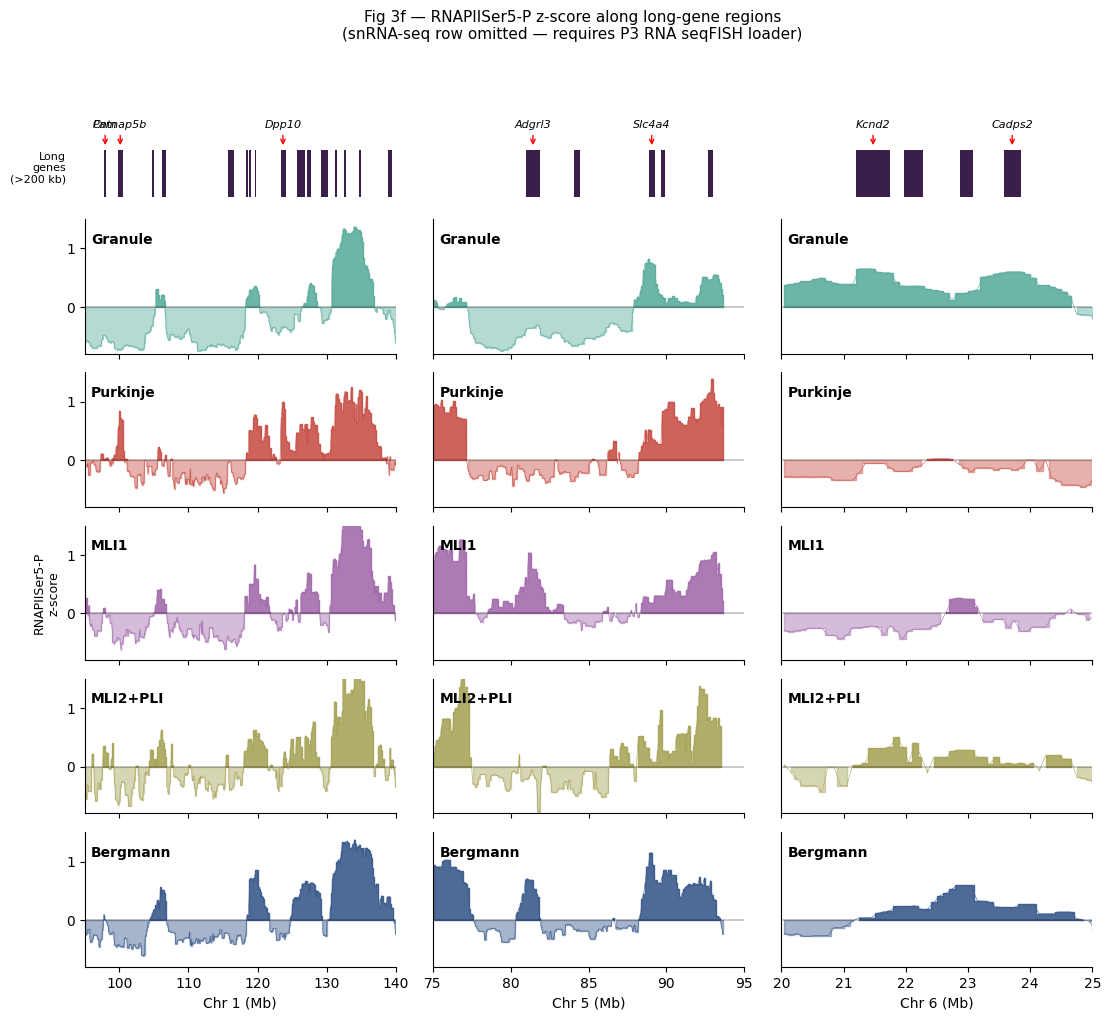

In [17]:
REGIONS_3F = [
    ('chr1', 95.0, 140.0),
    ('chr5', 75.0,  95.0),
    ('chr6', 20.0,  25.0),
]
CELL_TYPES_3F = ['Granule', 'Purkinje', 'MLI1', 'MLI2+PLI', 'Bergmann']
CT_COLOR_3F = {
    'Granule':  '#5cad9e', 'Purkinje': '#c95249', 'MLI1':     '#a36cad',
    'MLI2+PLI': '#a8a55a', 'Bergmann': '#3b5b8c',
}
NAMED_GENES = {'Pam', 'Cntnap5b', 'Dpp10',
               'Adgrl3', 'Slc4a4', 'Kcnd2', 'Cadps2'}
BIN_SIZE_3F = 100_000
SMOOTH_3F   = 5

def load_long_genes(chroms):
    gene_csv = Path('/Volumes/Extreme SSD/U-Chrom/dna-seqfish-plus-multi-omics/'
                    'data/annotation/mm10_25kb_bins_genes_09022022.csv')
    if not gene_csv.exists():
        return pd.DataFrame(columns=['chrom','gene','start','end','length'])
    ann = pd.read_csv(gene_csv, low_memory=False)
    ann = ann[ann['chrom'].isin(chroms) & (ann['gene'] != '.')]
    spans = (ann.groupby(['chrom', 'gene'])
                .agg(start=('start', 'min'), end=('end', 'max')))
    spans['length'] = spans['end'] - spans['start']
    return spans[spans['length'] >= 200_000].reset_index()

def per_ct_region_track(cd, cell_type, chrom, start_mb, end_mb):
    cells_ct = cd.cells.index[cd.cells['cell_type'] == cell_type]
    sub = cd.get_chrom(chrom) if chrom in cd.chroms else None
    if sub is None or sub.n_spots == 0:
        return None, None
    mask = sub.spots['cell_id'].astype(str).isin(cells_ct).to_numpy()
    if mask.sum() == 0: return None, None
    starts = sub.spots['start'].astype(np.int64).to_numpy()[mask]
    in_region = (starts >= start_mb*1e6) & (starts < end_mb*1e6)
    if in_region.sum() == 0: return None, None
    starts = starts[in_region]
    vals = sub.tracks['RNAPIISer5-P'].iloc[mask].to_numpy()[in_region]
    bins = (starts // BIN_SIZE_3F).astype(np.int64)
    df = pd.DataFrame({'_bin': bins, 'v': vals})
    bin_med = df.groupby('_bin', observed=True)['v'].median()
    grid = np.arange(int(start_mb*1e6 // BIN_SIZE_3F),
                     int(end_mb*1e6 // BIN_SIZE_3F) + 1)
    s = bin_med.reindex(grid).rolling(SMOOTH_3F, min_periods=1, center=True).median()
    x = (grid * BIN_SIZE_3F + BIN_SIZE_3F/2) / 1e6
    return x, s.values

long_genes = load_long_genes([r[0] for r in REGIONS_3F])

fig = plt.figure(figsize=(13, 11))
gs = fig.add_gridspec(nrows=6, ncols=3,
                      height_ratios=[0.6, 1, 1, 1, 1, 1],
                      hspace=0.15, wspace=0.12)

for col, (chrom, s_mb, e_mb) in enumerate(REGIONS_3F):
    ax = fig.add_subplot(gs[0, col])
    if len(long_genes):
        sub_g = long_genes[(long_genes['chrom'] == chrom)
                           & (long_genes['end']   > s_mb*1e6)
                           & (long_genes['start'] < e_mb*1e6)]
        for _, g in sub_g.iterrows():
            x0 = max(g['start'], s_mb*1e6) / 1e6
            x1 = min(g['end'],   e_mb*1e6) / 1e6
            ax.add_patch(Rectangle((x0, 0.05), x1 - x0, 0.7,
                                   facecolor='#3a1f4a', edgecolor='none'))
            if g['gene'] in NAMED_GENES:
                mid = (x0 + x1) / 2
                ax.annotate(g['gene'], xy=(mid, 0.78), xytext=(mid, 1.05),
                            ha='center', va='bottom', fontsize=8, fontstyle='italic',
                            arrowprops=dict(arrowstyle='->', color='red', lw=1))
    ax.set_xlim(s_mb, e_mb); ax.set_ylim(0, 1.2)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ('top','right','left','bottom'): ax.spines[sp].set_visible(False)
    if col == 0:
        ax.text(-0.06, 0.4, 'Long\ngenes\n(>200 kb)', transform=ax.transAxes,
                ha='right', va='center', fontsize=8)

for row, ct in enumerate(CELL_TYPES_3F, start=1):
    for col, (chrom, s_mb, e_mb) in enumerate(REGIONS_3F):
        ax = fig.add_subplot(gs[row, col])
        x, y = per_ct_region_track(cd, ct, chrom, s_mb, e_mb)
        if x is None:
            ax.text(0.5, 0.5, f'no data\n{ct} {chrom}', ha='center', va='center',
                    transform=ax.transAxes, fontsize=8)
            ax.set_xticks([]); ax.set_yticks([]); continue
        c = CT_COLOR_3F[ct]
        ax.fill_between(x, 0, y, where=(y > 0), color=c, alpha=0.9, step='mid')
        ax.fill_between(x, 0, y, where=(y < 0), color=c, alpha=0.45, step='mid')
        ax.plot(x, y, color=c, lw=0.4)
        ax.axhline(0, color='k', lw=0.3)
        ax.set_xlim(s_mb, e_mb); ax.set_ylim(-0.8, 1.5)
        ax.text(0.02, 0.82, ct, transform=ax.transAxes,
                fontsize=10, fontweight='bold')
        if row == len(CELL_TYPES_3F):
            ax.set_xlabel(f'Chr {chrom[3:]} (Mb)', fontsize=10)
        else:
            ax.set_xticklabels([])
        if col == 0:
            ax.set_yticks([0, 1])
            if row == 3:
                ax.set_ylabel('RNAPIISer5-P\nz-score', fontsize=9)
        else:
            ax.set_yticks([])
        for sp in ('top', 'right'): ax.spines[sp].set_visible(False)

fig.suptitle('Fig 3f — RNAPIISer5-P z-score along long-gene regions\n'
             '(snRNA-seq row omitted — requires P3 RNA seqFISH loader)',
             fontsize=11)
plt.show()


## 5. Framework gap notes

What this walkthrough taught us about the current `ChromData` /
`uchrom.io.seqfish_multiomics` surface:

### Currently sufficient

- `coords`, `spots[chrom/start/end/trace_id/cell_id]`, the 62
  `tracks` columns, `cells['cell_type']`, `cellm['umap']` and the
  3 subset accessors (`get_chrom`, `get_cell`, `get_trace`) are enough
  to reproduce **all five** paper panels above.  No "missing field"
  blocked any of them.

### Known data gaps (loader roadmap)

| What | Loader phase |
|---|---|
| `cellm['if_mean']` (27-marker per-cell IF mean) | **P2** |
| RNA seqFISH spots (intron / non-barcoded mRNA) | **P3** |
| scRNA reference matrix (needed for Fig 3f snRNA-seq panel) | **P3+** |

### Algorithm-level gaps (downstream modules)

Several inline helpers above are *prototype* implementations that
deserve a proper home:

| Inline helper | Should live in |
|---|---|
| `per_ct_chrom_mean_structure` | `uchrom.strc.comp.eigenvector_from_distance` (with proper per-trace pipeline) |
| `compute_inter_chrom_pairs` + `top5_keys` | `uchrom.fea.inter_chrom_distances` (with marker-stratified filter) |
| `per_ct_region_track` | `uchrom.fea.per_ct_track_signal` (1-D pseudo-bigwig from FISH) |

These are the natural next-PR boundaries.
